# 07 - RAG system evaluation

Question: does grounding the LLM in retrieved abstracts make its answers more accurate than asking it without any evidence?

SciFact dev claims have gold labels (SUPPORT / CONTRADICT / NOT_ENOUGH_INFO), so we can score the generator directly. The model is asked to give a verdict on each claim, and we compare four conditions on the same claims:

| condition | context given to the LLM |
|---|---|
| `no_retrieval` | nothing, the model uses its own knowledge |
| `bm25` | top-k abstracts from BM25 |
| dense (`bge`) | top-k abstracts from BGE |
| `gold_evidence` | the annotated evidence abstracts (upper bound) |

Needs a `GEMINI_API_KEY` in `.env`. Responses are cached on disk so a crash or rate limit doesn't mean starting over.

In [ ]:
import os, sys, re, json, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from dotenv import load_dotenv

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / ".env")

from retrieval.data import load_corpus, load_claims
from retrieval.search import get_retriever

RESULTS = ROOT / "results" / "rag"
RESULTS.mkdir(parents=True, exist_ok=True)

## 1. Settings

`N_CLAIMS` is kept small on purpose, each condition costs one API call per claim. Raise it if your quota allows.

Check `MODEL_NAME` against the Gemini models that are available to your key. It is set to the same name used in `backend/generator.py`.

In [ ]:
SEED = 42
N_CLAIMS = 60          # claims sampled from dev
TOP_K = 3              # abstracts given to the LLM
DENSE_METHOD = "bge"   # which dense retriever to test ("bge" or "minilm")
MODEL_NAME = os.getenv("GEMINI_MODEL", "gemini-3.5-flash-lite")
DELAY = 4              # seconds between calls, helps with free-tier rate limits
DRY_RUN = False        # True = fake random answers, only for testing the pipeline

API_KEY = os.getenv("GEMINI_API_KEY")
if not API_KEY and not DRY_RUN:
    raise RuntimeError("No GEMINI_API_KEY found in .env (set DRY_RUN = True just to test the code)")
if DRY_RUN:
    DELAY = 0
    print("DRY RUN: answers are random, do NOT use these numbers in the report")

LABELS = ["SUPPORT", "CONTRADICT", "NOT_ENOUGH_INFO"]
CONDITIONS = ["no_retrieval", "bm25", DENSE_METHOD, "gold_evidence"]

## 2. Data and sample

In [ ]:
corpus = load_corpus()
doc_by_id = {d["id"]: d for d in corpus}
dev_claims = load_claims("dev")


def gold_label(claim):
    labels = {e["label"] for ev in claim["evidence"].values() for e in ev}
    if not labels:
        return "NOT_ENOUGH_INFO"
    assert len(labels) == 1, claim["id"]
    return labels.pop()


rng = random.Random(SEED)
sample = rng.sample(dev_claims, N_CLAIMS)
gold = {c["id"]: gold_label(c) for c in sample}

print(pd.Series(gold).value_counts())

SUPPORT            29
NOT_ENOUGH_INFO    19
CONTRADICT         12
Name: count, dtype: int64


## 3. Retrieval and prompt

For `gold_evidence`, claims with evidence get their annotated abstracts. NOT_ENOUGH_INFO claims have no evidence, so they get the abstract they were written from (`cited_doc_ids`), which is how SciFact sets up that case.

In [ ]:
retrievers = {m: get_retriever(m) for m in set(CONDITIONS) - {"no_retrieval", "gold_evidence"}}


def get_context(cond, claim, k=TOP_K):
    if cond == "no_retrieval":
        return []
    if cond == "gold_evidence":
        ids = list(claim["evidence"]) or list(claim["cited_doc_ids"])
        return [doc_by_id[str(i)] for i in ids if str(i) in doc_by_id][:k]
    hits = retrievers[cond].search([claim["claim"]], k=k)[0]
    return [doc_by_id[doc_id] for doc_id, _ in hits]


SYSTEM_WITH_CONTEXT = (
    "You are checking a scientific claim against evidence. Use ONLY the abstracts provided. "
    "Decide whether they SUPPORT the claim, CONTRADICT it, or do not contain enough information (NOT_ENOUGH_INFO). "
    "Cite the Document IDs you relied on."
)
SYSTEM_NO_CONTEXT = (
    "You are checking a scientific claim. No documents are provided, so use your own knowledge. "
    "Decide whether the claim is SUPPORT (true), CONTRADICT (false) or NOT_ENOUGH_INFO."
)
FORMAT_HINT = (
    'Reply with JSON only, no other text: '
    '{"verdict": "SUPPORT" | "CONTRADICT" | "NOT_ENOUGH_INFO", '
    '"rationale": "one or two sentences", "citations": ["doc id", ...]}'
)


def build_prompt(claim_text, docs):
    if not docs:
        return SYSTEM_NO_CONTEXT, f"Claim: {claim_text}\n\n{FORMAT_HINT}"
    blocks = [f"Document ID: {d['id']}\nTitle: {d['title']}\nAbstract: {d['abstract']}" for d in docs]
    context = "\n\n---\n\n".join(blocks)
    return SYSTEM_WITH_CONTEXT, f"Abstracts:\n{context}\n\nClaim: {claim_text}\n\n{FORMAT_HINT}"

c:\Users\sabaj\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2884.18it/s]


## 4. Calling the model

Every reply is appended to a cache file keyed by model, condition, k and claim id, so re-running the notebook only calls the API for things it hasn't seen.

In [11]:
if not DRY_RUN:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=API_KEY)


def call_llm(system, prompt, retries=4):
    if DRY_RUN:
        verdict = random.choice(LABELS)
        return json.dumps({"verdict": verdict, "rationale": "dry run", "citations": []})
    for attempt in range(retries):
        try:
            resp = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt,
                config=types.GenerateContentConfig(system_instruction=system, temperature=0.0),
            )
            return resp.text
        except Exception as e:
            wait = 5 * 2 ** attempt
            print(f"API error ({e}), retrying in {wait}s")
            time.sleep(wait)
    return None


def parse_reply(text):
    if not text:
        return None
    m = re.search(r"\{.*\}", text, re.S)
    if not m:
        return None
    try:
        data = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    verdict = str(data.get("verdict", "")).upper().strip().replace(" ", "_")
    verdict = {"SUPPORTS": "SUPPORT", "CONTRADICTS": "CONTRADICT"}.get(verdict, verdict)
    if verdict not in LABELS:
        return None
    cites = [str(c).strip() for c in data.get("citations", []) or []]
    return {"verdict": verdict, "rationale": data.get("rationale", ""), "citations": cites}


CACHE_FILE = RESULTS / ("llm_cache_dryrun.jsonl" if DRY_RUN else "llm_cache.jsonl")
cache = {}
if CACHE_FILE.exists():
    for line in CACHE_FILE.read_text().splitlines():
        row = json.loads(line)
        cache[row["key"]] = row["reply"]
print("cached replies:", len(cache))

cached replies: 0


In [12]:
def run_condition(cond, claims, k=TOP_K):
    rows = []
    for i, claim in enumerate(claims, start=1):
        docs = get_context(cond, claim, k)
        ctx_ids = [d["id"] for d in docs]

        key = f"{MODEL_NAME}|{cond}|k{k}|{claim['id']}"
        if key in cache:
            reply = cache[key]
        else:
            system, prompt = build_prompt(claim["claim"], docs)
            reply = call_llm(system, prompt)
            if reply is not None:
                cache[key] = reply
                with open(CACHE_FILE, "a") as f:
                    f.write(json.dumps({"key": key, "reply": reply}) + "\n")
            time.sleep(DELAY)

        parsed = parse_reply(reply)
        gold_docs = {str(d) for d in claim["evidence"]}
        cited = parsed["citations"] if parsed else []
        rows.append({
            "claim_id": claim["id"],
            "gold": gold[claim["id"]],
            "pred": parsed["verdict"] if parsed else "UNPARSED",
            "rationale": parsed["rationale"] if parsed else "",
            "n_cited": len(cited),
            "n_valid_cited": sum(c in ctx_ids for c in cited),
            "retrieval_hit": bool(gold_docs & set(ctx_ids)) if gold_docs else None,
        })
        if i % 10 == 0:
            print(f"  {cond}: {i}/{len(claims)}")
    df = pd.DataFrame(rows)
    df["correct"] = df["pred"] == df["gold"]
    return df

## 5. Run all conditions

In [ ]:
results = {}
for cond in CONDITIONS:
    print("condition:", cond)
    results[cond] = run_condition(cond, sample)
    results[cond].to_csv(RESULTS / f"predictions_{cond}_k{TOP_K}.csv", index=False)

condition: no_retrieval
  no_retrieval: 10/60
  no_retrieval: 20/60
  no_retrieval: 30/60
  no_retrieval: 40/60
  no_retrieval: 50/60
  no_retrieval: 60/60
condition: bm25
  bm25: 10/60
  bm25: 20/60
  bm25: 30/60
  bm25: 40/60
  bm25: 50/60


## 6. Scores

In [ ]:
def summarise(df):
    cited = df["n_cited"].sum()
    return {
        "accuracy": accuracy_score(df["gold"], df["pred"]),
        "macro_F1": f1_score(df["gold"], df["pred"], labels=LABELS, average="macro", zero_division=0),
        "unparsed": int((df["pred"] == "UNPARSED").sum()),
        "valid_citation_rate": df["n_valid_cited"].sum() / cited if cited else np.nan,
    }

summary = pd.DataFrame({c: summarise(df) for c, df in results.items()}).T.round(3)
summary.to_csv(RESULTS / f"rag_summary_k{TOP_K}.csv")
display(summary)

""


KeyError: "None of [Index(['accuracy', 'macro_F1'], dtype='str')] are in the [columns]"

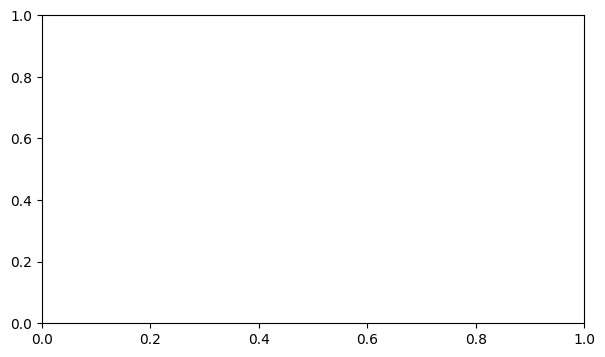

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
summary[["accuracy", "macro_F1"]].plot(kind="bar", ax=ax, width=0.7)
ax.set_ylim(0, 1)
ax.set_ylabel("score")
ax.set_title(f"Verdict quality by condition (n={len(sample)}, top-{TOP_K})")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(RESULTS / "rag_conditions.png", dpi=150)
plt.show()

### Per-class recall and confusion matrices

Accuracy alone can hide which class is going wrong (models tend to over-predict NOT_ENOUGH_INFO or SUPPORT).

In [10]:
per_class = {}
for cond, df in results.items():
    per_class[cond] = {
        lab: (df[df["gold"] == lab]["pred"] == lab).mean() for lab in LABELS
    }
display(pd.DataFrame(per_class).T.round(3))

for cond, df in results.items():
    cm = confusion_matrix(df["gold"], df["pred"], labels=LABELS + ["UNPARSED"])
    print(cond)
    display(pd.DataFrame(cm[:3], index=[f"gold {l}" for l in LABELS], columns=LABELS + ["UNPARSED"]))

""


## 7. Does retrieval quality carry through to the answer?

For claims that have gold evidence, split the retrieval conditions into "a gold abstract was in the top-k" and "it was missed", and compare verdict accuracy.

In [11]:
rows = []
for cond in CONDITIONS:
    if cond in ("no_retrieval", "gold_evidence"):
        continue
    df = results[cond]
    df = df[df["retrieval_hit"].notna()]
    for hit, grp in df.groupby("retrieval_hit"):
        rows.append({"condition": cond, "gold doc in top-k": hit, "n": len(grp),
                     "accuracy": round(grp["correct"].mean(), 3)})
display(pd.DataFrame(rows))

NameError: name 'CONDITIONS' is not defined

## 8. Is the gap between conditions real?

Paired bootstrap on per-claim correctness (same claims in every condition). With only a few dozen claims the intervals will be wide, so be careful about what you claim.

In [12]:
def paired_bootstrap(a, b, n_boot=10000, seed=SEED):
    rng = np.random.default_rng(seed)
    diff = a.astype(float).values - b.astype(float).values
    idx = rng.integers(0, len(diff), size=(n_boot, len(diff)))
    means = diff[idx].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    p = min(1.0, 2 * min((means <= 0).mean(), (means >= 0).mean()))
    return diff.mean(), lo, hi, p

correct = {c: df.set_index("claim_id")["correct"] for c, df in results.items()}
pairs = [(DENSE_METHOD, "no_retrieval"), ("bm25", "no_retrieval"),
         (DENSE_METHOD, "bm25"), ("gold_evidence", DENSE_METHOD)]

rows = []
for a, b in pairs:
    diff, lo, hi, p = paired_bootstrap(correct[a], correct[b])
    rows.append({"A": a, "B": b, "accuracy diff (A-B)": round(diff, 3),
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]", "p": round(p, 4)})
display(pd.DataFrame(rows))

KeyError: 'bge'

## 9. Look at some answers

Read a few by hand, this is where the interesting points for the report come from.

In [13]:
claim_by_id = {c["id"]: c["claim"] for c in sample}
df = results[DENSE_METHOD]

def show(rows, n=4):
    for _, r in rows.head(n).iterrows():
        print("claim    :", claim_by_id[r["claim_id"]])
        print("gold     :", r["gold"], "| predicted:", r["pred"])
        print("rationale:", r["rationale"])
        print("-" * 80)

print(f"=== wrong with {DENSE_METHOD} retrieval ===")
show(df[~df["correct"]])

fixed = df.merge(results["no_retrieval"][["claim_id", "correct"]], on="claim_id", suffixes=("", "_none"))
print("=== right with retrieval, wrong without ===")
show(fixed[fixed["correct"] & ~fixed["correct_none"]])
print("=== right without retrieval, wrong with ===")
show(fixed[~fixed["correct"] & fixed["correct_none"]])

KeyError: 'bge'

## 10. Optional: how many abstracts to give the model?

Set `RUN_K_ABLATION = True` to repeat the dense condition with k = 1, 3 and 5. This costs extra API calls (cached ones are free).

In [14]:
RUN_K_ABLATION = False

if RUN_K_ABLATION:
    rows = []
    for k in [1, 3, 5]:
        df_k = run_condition(DENSE_METHOD, sample, k=k)
        s = summarise(df_k)
        rows.append({"k": k, "accuracy": round(s["accuracy"], 3), "macro_F1": round(s["macro_F1"], 3),
                     "valid_citation_rate": round(s["valid_citation_rate"], 3)})
    display(pd.DataFrame(rows))